<a href="https://colab.research.google.com/github/xayrullofayzullaev13-netizen/week10_lab/blob/main/Lab_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE206 Fundamental of Machine Learning
## Lab: Support Vector Machine (SVM) Classification

| | |
|---|---|
| **Course code** | CSE206 |
| **Topic** | Linear and kernel SVMs, effect of the margin and the C parameter, performance evaluation |
| **Duration** | 2 hours |
| **Session 1 (about 60 min)** | Part A: guided walkthrough with explanations and examples |
| **Session 2 (about 60 min)** | Part B: graded exercises, 3 exercises, 100 marks (target: 30 minutes) |

### What you will learn today

By the end of this lab you should be able to:

1. Explain what an SVM does: decision boundary, margin and support vectors.
2. Train a linear SVM with scikit-learn and draw its boundary.
3. Describe how the **C** parameter changes the margin.
4. Explain why we need **kernels** for data that cannot be separated by a straight line.

---
# Part A: Guided Walkthrough (Session 1)

## A0. Setup

First we load the tools we need. Everything comes from three libraries you already know:

- **NumPy** for arrays of numbers
- **Matplotlib** for plots
- **scikit-learn** (`sklearn`) for datasets, the SVM model and the evaluation tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_circles, make_moons, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("All libraries loaded.")

All libraries loaded.


### A helper function for drawing

The next cell defines a function called `plot_svm`. **You do not need to understand every line of it.**
You only need to know how to use it:

```python
plot_svm(model, X, y, "My title")
```

It draws:

- the data points (blue for class 0, red for class 1),
- the **decision boundary** as a solid black line,
- the **margin** as two dashed black lines,
- the **support vectors** with green circles around them.

In [2]:
def plot_svm(model, X, y, title="", ax=None):
    # Create a new figure if no axis is given
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    # 1. Draw the data points
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k", s=35)

    # 2. Make a grid of points that covers the whole picture
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # 3. Ask the model for its score on every grid point
    #    score = 0 is the boundary, score = -1 and +1 are the margin lines
    Z = model.decision_function(grid).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"])

    # 4. Circle the support vectors
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=130, facecolors="none",
               edgecolors="green", linewidths=1.5, label="support vectors")

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend(loc="lower right")

print("plot_svm is ready to use.")

plot_svm is ready to use.


## A1. What is a Support Vector Machine?

An SVM is a **classifier**: it learns to put each data point into a class (for example "spam" or "not spam").

Imagine two groups of points on a sheet of paper. Many different straight lines could separate them.
**Which line should we choose?**

SVM's answer: choose the line that stays **as far as possible from both groups**.

Think of it as building the **widest possible road** between two villages:

- The **middle line of the road** is the **decision boundary**. Points on one side are class 0, on the other side class 1.
- The **width of the road** is the **margin**.
- The houses that **touch the edge of the road** are the **support vectors**. They are the closest points to the boundary.

```
   class 0                                class 1
      o                                      x
   o      o    |  - - - -|- - - -  |      x     x
     o    (o)  |         |         | (x)     x
   o           |         |         |       x
      o        |  margin | margin  |    x
         edge of road  boundary  edge of road
```

(The points in brackets are the support vectors.)

### Key words

| Word | Simple meaning |
|---|---|
| Decision boundary | The line (or surface) that separates the classes |
| Margin | The distance from the boundary to the closest points |
| Support vectors | The training points closest to the boundary. Only these points decide where the boundary goes |
| Hyperplane | The general name for the boundary. With 2 features it is a line, with 3 features a flat plane |

**Why "the widest road"?** A wide margin leaves a safety gap. New points that are a little different
from the training points are still likely to land on the correct side.

## A2. Example 1: A linear SVM on simple data

We start with a small, made-up dataset of 40 points with 2 features, where the two classes are clearly apart.

`make_blobs` creates groups ("blobs") of points for us.

Shape of X: (40, 2)
Labels y: [1 0 1 0 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1 1 1 0 0 1 1 0 1 1 1 1 0 0 0 0
 1 0 1]


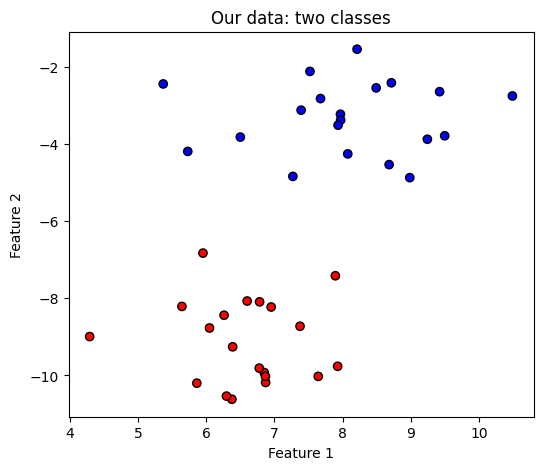

In [3]:
# Create 40 points in 2 groups
X, y = make_blobs(n_samples=40, centers=2, random_state=6)

print("Shape of X:", X.shape)   # 40 rows (points), 2 columns (features)
print("Labels y:", y)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Our data: two classes")
plt.show()

### Training the model

Every scikit-learn model is used in the same 3 steps:

1. **Create** the model: `model = SVC(...)`
2. **Train** it on data: `model.fit(X, y)`
3. **Use** it to predict: `model.predict(new_points)`

`SVC` means *Support Vector Classifier*. `kernel="linear"` tells it to use a straight line.

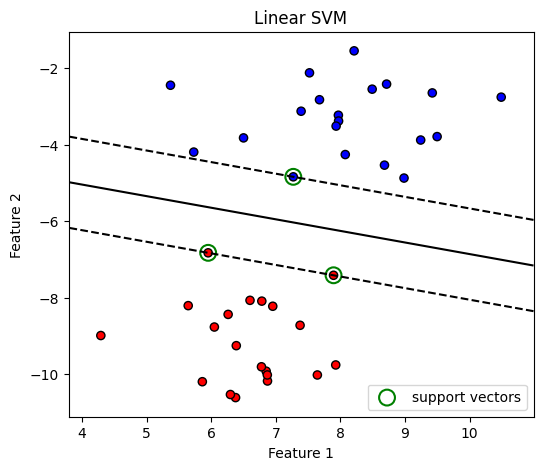

In [4]:
# Step 1: create the model
model = SVC(kernel="linear", C=1)

# Step 2: train the model
model.fit(X, y)

# Draw the result
plot_svm(model, X, y, "Linear SVM")
plt.show()

**Look at the picture:**

- The solid line is the decision boundary.
- The dashed lines show the margin. No training point is inside the road.
- Only a few points (green circles) touch the margin. These are the support vectors.
  If we deleted any other point, the boundary would **not move at all**.

In [5]:
print("Number of support vectors in each class:", model.n_support_)
print("Total number of support vectors:", len(model.support_vectors_))
print()
print("The support vectors are:")
print(model.support_vectors_)

Number of support vectors in each class: [1 2]
Total number of support vectors: 3

The support vectors are:
[[ 7.27059007 -4.84225716]
 [ 5.95313618 -6.82945967]
 [ 7.89359985 -7.41655113]]


### The equation of the line

A linear SVM learns a line of the form

$$ w_1 \cdot x_1 + w_2 \cdot x_2 + b = 0 $$

- `w1, w2` are the **weights** (`model.coef_`)
- `b` is the **bias** (`model.intercept_`)

The width of the full road (from one dashed line to the other) is $\dfrac{2}{\|w\|}$, where $\|w\| = \sqrt{w_1^2 + w_2^2}$.

In [6]:
w = model.coef_[0]
b = model.intercept_[0]

print("Weights w =", w)
print("Bias b =", b)

margin_width = 2 / np.sqrt(w[0]**2 + w[1]**2)
print("Margin width =", round(margin_width, 3))

Weights w = [-0.2539717  -0.83806387]
Bias b = -3.211328260154494
Margin width = 2.284


### Step 3: predicting new points

Now we use the trained model on points it has never seen.
Note the **double brackets** `[[ ... ]]`: the model expects a 2-D array (a list of points), even for one point.

In [7]:
new_points = np.array([[6, -6],
                       [10, -2]])

predictions = model.predict(new_points)

for point, label in zip(new_points, predictions):
    print("Point", point, "is predicted as class", label)

Point [ 6 -6] is predicted as class 1
Point [10 -2] is predicted as class 0


## A3. Soft margin and the C parameter

Real data is messy. The classes often **overlap**, so no straight line separates them perfectly.

SVM handles this with a **soft margin**: some points are *allowed* to be inside the road or even on the wrong side,
but the model pays a **penalty** for each of them.

**C** controls how big that penalty is:

| | Small C (e.g. 0.01) | Large C (e.g. 100) |
|---|---|---|
| Attitude | "Mistakes are OK, keep the road wide" | "Avoid every mistake, even if the road is narrow" |
| Margin | Wide | Narrow |
| Number of support vectors | Many | Few |
| Training errors | More | Fewer |
| Danger | Too simple (underfitting) | Too fitted to the training data (overfitting) |

Let us see this with overlapping data.

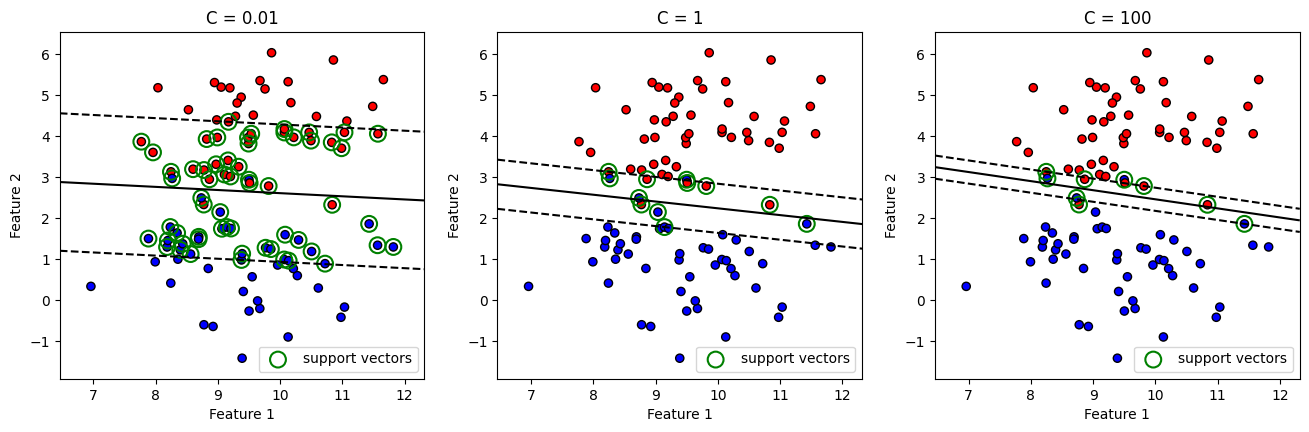

In [8]:
# Two groups that overlap a little (cluster_std controls how spread out the groups are)
X, y = make_blobs(n_samples=100, centers=2, cluster_std=1.0, random_state=4)

C_values = [0.01, 1, 100]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i in range(3):
    C = C_values[i]
    model = SVC(kernel="linear", C=C)
    model.fit(X, y)
    plot_svm(model, X, y, "C = " + str(C), ax=axes[i])

plt.show()

In [9]:
print("C       | support vectors | margin width | training accuracy")
print("-" * 62)

for C in C_values:
    model = SVC(kernel="linear", C=C)
    model.fit(X, y)

    w = model.coef_[0]
    width = 2 / np.sqrt(w[0]**2 + w[1]**2)
    train_acc = model.score(X, y)      # score() gives the accuracy

    print(f"{C:<7} | {len(model.support_vectors_):<15} | {width:<12.3f} | {train_acc:.2f}")

C       | support vectors | margin width | training accuracy
--------------------------------------------------------------
0.01    | 60              | 3.340        | 0.96
1       | 12              | 1.182        | 0.96
100     | 9               | 0.551        | 0.97


**What do we see?**

- With **C = 0.01** the road is very wide and many points are support vectors. The model is relaxed about mistakes.
- With **C = 100** the road is narrow and only a few points are support vectors. The model tries hard to classify every training point.

**Question for the class:** a larger C gave a narrower margin and slightly higher training accuracy. Does that mean large C is always better?
(Hint: we only measured accuracy on the **training** data. We come back to this in A7.)

## A4. When a straight line is not enough: kernels

Look at the data below. One class forms an inner circle and the other class an outer ring.
**No straight line** can separate them.

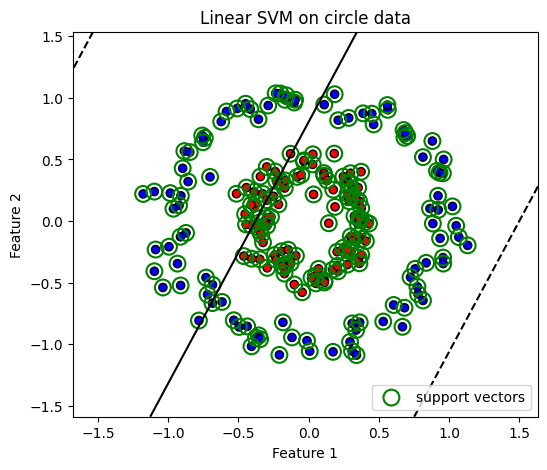

Training accuracy of the linear SVM: 0.62


In [10]:
X, y = make_circles(n_samples=200, factor=0.4, noise=0.08, random_state=0)

linear_model = SVC(kernel="linear", C=1)
linear_model.fit(X, y)

plot_svm(linear_model, X, y, "Linear SVM on circle data")
plt.show()

print("Training accuracy of the linear SVM:", round(linear_model.score(X, y), 2))

The linear SVM fails: its accuracy is only a little better than tossing a coin (which would give 0.5).

### The idea behind kernels: add a new feature

What if we add a third feature, the squared distance from the centre?

$$ z = x_1^2 + x_2^2 $$

Points of the inner circle have a **small** z, points of the outer ring have a **large** z.
In this new view, a simple **straight (horizontal) line** separates the classes.

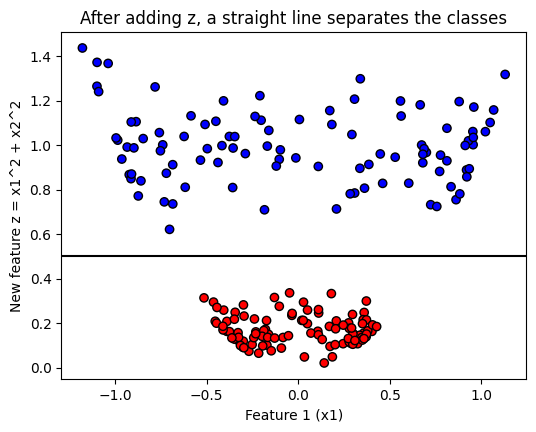

In [11]:
z = X[:, 0]**2 + X[:, 1]**2      # new feature

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], z, c=y, cmap="bwr", edgecolors="k")
plt.axhline(0.5, color="k", linestyle="-")
plt.xlabel("Feature 1 (x1)")
plt.ylabel("New feature z = x1^2 + x2^2")
plt.title("After adding z, a straight line separates the classes")
plt.show()

This is exactly what a **kernel** does. It lets the SVM work as if the data had extra features,
**without us having to create them by hand**. This shortcut is called the **kernel trick**.

A straight boundary in the bigger space looks like a **curved** boundary when we draw it back in the original 2-D picture.

### Common kernels in scikit-learn

| Kernel | Code | Boundary shape | Extra parameter |
|---|---|---|---|
| Linear | `SVC(kernel="linear")` | Straight line | C |
| Polynomial | `SVC(kernel="poly", degree=2)` | Curves (parabola, ellipse, ...) | C, degree |
| RBF (Radial Basis Function) | `SVC(kernel="rbf")` | Very flexible curves and islands | C, gamma |

**RBF is the default** in scikit-learn and the most commonly used kernel.

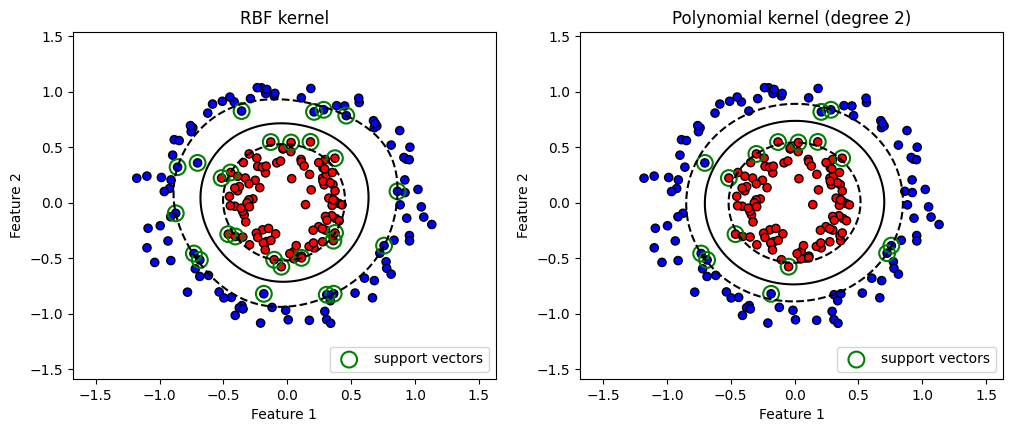

Training accuracy, RBF kernel:        1.0
Training accuracy, polynomial kernel: 1.0


In [12]:
rbf_model = SVC(kernel="rbf", C=1)
rbf_model.fit(X, y)

poly_model = SVC(kernel="poly", degree=2, C=1)
poly_model.fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_svm(rbf_model, X, y, "RBF kernel", ax=axes[0])
plot_svm(poly_model, X, y, "Polynomial kernel (degree 2)", ax=axes[1])
plt.show()

print("Training accuracy, RBF kernel:       ", round(rbf_model.score(X, y), 2))
print("Training accuracy, polynomial kernel:", round(poly_model.score(X, y), 2))

Both kernels draw a closed curve around the inner circle, and the accuracy jumps close to 1.0.

## A5. The gamma parameter of the RBF kernel

The RBF kernel has one more setting, **gamma**. It controls how far the influence of a single training point reaches.

| | Small gamma (e.g. 0.1) | Large gamma (e.g. 50) |
|---|---|---|
| Each point influences | A large area | Only a tiny area around itself |
| Boundary | Smooth, simple | Wiggly, wraps around single points |
| Danger | Underfitting | Overfitting |

If you do not set gamma, scikit-learn uses `gamma="scale"`, which is usually a good starting value.

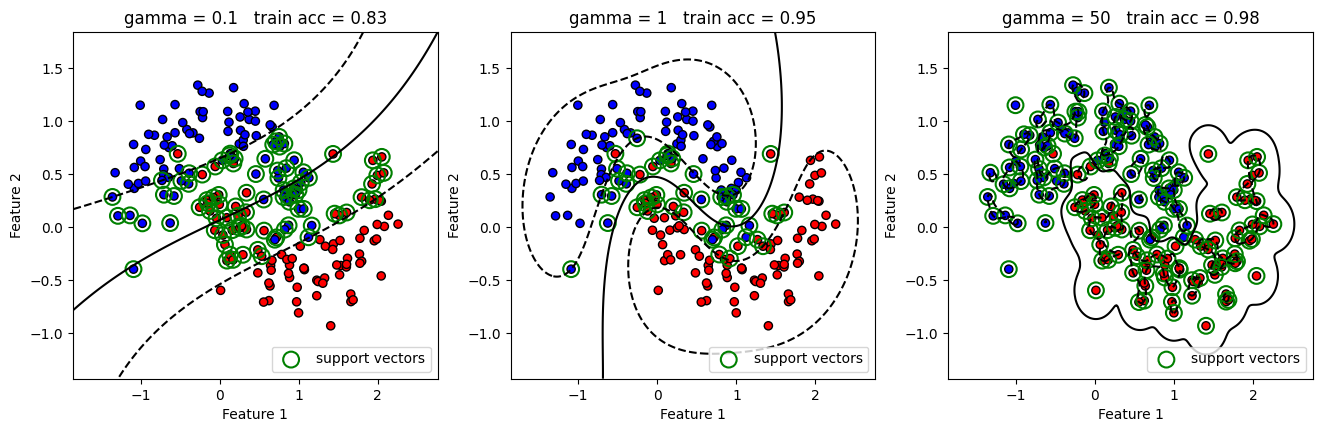

In [13]:
X, y = make_moons(n_samples=200, noise=0.2, random_state=0)

gamma_values = [0.1, 1, 50]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i in range(3):
    g = gamma_values[i]
    model = SVC(kernel="rbf", C=1, gamma=g)
    model.fit(X, y)
    title = "gamma = " + str(g) + "   train acc = " + str(round(model.score(X, y), 2))
    plot_svm(model, X, y, title, ax=axes[i])

plt.show()

- **gamma = 0.1**: the boundary is almost straight. It is too simple for the moon shapes (underfitting).
- **gamma = 1**: a smooth curve that follows the moons. This looks right.
- **gamma = 50**: the boundary draws small islands around single points. Training accuracy is high, but this model has
  memorised the noise and will do badly on new data (overfitting).

**C and gamma work together.** Both large C and large gamma make the model more complex.

## A6. Performance evaluation on a real dataset

So far we measured accuracy on the same points we trained on. That is like giving students the exam questions
before the exam: a high score does not prove they learned anything.

The correct way is:

1. **Split** the data into a **training set** (to learn) and a **test set** (to check).
2. Train only on the training set.
3. Measure performance on the test set, which the model has never seen.

### The dataset: Breast Cancer Wisconsin

- 569 tumour samples, 30 numeric features (radius, texture, area, smoothness, ...)
- Target: **0 = malignant** (cancer), **1 = benign** (not cancer)

In [14]:
data = load_breast_cancer()
X = data.data
y = data.target

print("Shape of X:", X.shape)
print("Class names:", data.target_names)
print("Number of malignant (0):", np.sum(y == 0))
print("Number of benign (1):   ", np.sum(y == 1))

Shape of X: (569, 30)
Class names: ['malignant' 'benign']
Number of malignant (0): 212
Number of benign (1):    357


### Step 1: Train / test split

- `test_size=0.25` keeps 25% of the data for testing.
- `random_state=42` makes the split the same every time we run it.
- `stratify=y` keeps the same proportion of each class in both parts.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Test samples:    ", X_test.shape[0])

Training samples: 426
Test samples:     143


### Step 2: Feature scaling (very important for SVM)

SVM works with **distances** between points. If one feature has big numbers and another has small numbers,
the big feature dominates the distance and the small one is almost ignored.

In [16]:
print("Feature 'mean area':       min =", X_train[:, 3].min(), "  max =", X_train[:, 3].max())
print("Feature 'mean smoothness': min =", X_train[:, 4].min(), "  max =", X_train[:, 4].max())

Feature 'mean area':       min = 143.5   max = 2499.0
Feature 'mean smoothness': min = 0.06251   max = 0.1425


"Mean area" goes up to about 2500, while "mean smoothness" stays below 0.2.

`StandardScaler` rescales every feature so that it has **mean 0** and **standard deviation 1**.

**Rule:** `fit` the scaler on the **training data only**, then use it to `transform` both sets.
The test set must stay "unseen", so we do not let it influence the scaling.

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn mean and std from training data, then scale
X_test_scaled = scaler.transform(X_test)         # use the same mean and std on the test data

print("After scaling, 'mean area':       min =", round(X_train_scaled[:, 3].min(), 2), "  max =", round(X_train_scaled[:, 3].max(), 2))
print("After scaling, 'mean smoothness': min =", round(X_train_scaled[:, 4].min(), 2), "  max =", round(X_train_scaled[:, 4].max(), 2))

After scaling, 'mean area':       min = -1.46   max = 5.35
After scaling, 'mean smoothness': min = -2.51   max = 3.49


### Step 3: Does scaling really matter? Let us test it

In [18]:
# Model trained on the original (unscaled) data
model_unscaled = SVC(kernel="rbf", C=1)
model_unscaled.fit(X_train, y_train)
acc_unscaled = accuracy_score(y_test, model_unscaled.predict(X_test))

# Model trained on the scaled data
model = SVC(kernel="rbf", C=1)
model.fit(X_train_scaled, y_train)
acc_scaled = accuracy_score(y_test, model.predict(X_test_scaled))

print("Test accuracy WITHOUT scaling:", round(acc_unscaled, 3))
print("Test accuracy WITH scaling:   ", round(acc_scaled, 3))

Test accuracy WITHOUT scaling: 0.923
Test accuracy WITH scaling:    0.979


## A7. Choosing C: training accuracy versus test accuracy

Now we can answer the question from A3. We train SVMs with different values of C and compare
the accuracy on the **training** set with the accuracy on the **test** set.

In [19]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_scores = []
test_scores = []

for C in C_values:
    model = SVC(kernel="rbf", C=C)
    model.fit(X_train_scaled, y_train)
    train_scores.append(model.score(X_train_scaled, y_train))
    test_scores.append(model.score(X_test_scaled, y_test))

print("C       | train accuracy | test accuracy")
print("-" * 40)
for i in range(len(C_values)):
    print(f"{C_values[i]:<7} | {train_scores[i]:<14.3f} | {test_scores[i]:.3f}")

C       | train accuracy | test accuracy
----------------------------------------
0.001   | 0.627          | 0.629
0.01    | 0.627          | 0.629
0.1     | 0.962          | 0.937
1       | 0.979          | 0.979
10      | 0.993          | 0.979
100     | 1.000          | 0.944
1000    | 1.000          | 0.944


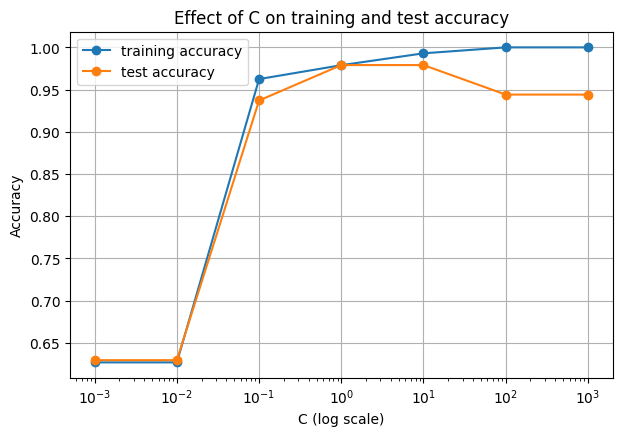

In [20]:
plt.figure(figsize=(7, 4.5))
plt.plot(C_values, train_scores, marker="o", label="training accuracy")
plt.plot(C_values, test_scores, marker="o", label="test accuracy")
plt.xscale("log")      # C values grow by 10x each step, so a log scale spaces them evenly
plt.xlabel("C (log scale)")
plt.ylabel("Accuracy")
plt.title("Effect of C on training and test accuracy")
plt.legend()
plt.grid(True)
plt.show()

**How to read this plot:**

- **Very small C** (left): both accuracies are low. The model is too simple: **underfitting**.
- **Very large C** (right): training accuracy reaches 1.0, but test accuracy does not improve and may drop.
  The model fits the training data too closely: **overfitting**.
- The best C is where the **test** accuracy is highest, not the training accuracy.

**A note on good practice:** here we used the test set to choose C, to keep things simple.
In real projects the test set is used only once, at the very end. C (and gamma) are chosen with a separate
validation set or with cross-validation. You will meet this in a later lab.

## A8. Summary of Part A

| Concept | Remember |
|---|---|
| SVM | Finds the boundary with the **widest margin** between classes |
| Support vectors | The closest points to the boundary; only they decide where it goes |
| C | Small C: wide margin, more mistakes allowed. Large C: narrow margin, fewer mistakes allowed |
| Kernel | Lets SVM draw **curved** boundaries (`linear`, `poly`, `rbf`) |
| gamma (RBF) | Small: smooth boundary. Large: wiggly boundary (risk of overfitting) |
| Scaling | Always use `StandardScaler` before an SVM. Fit on training data only |
| Evaluation | Use a **test set**. Look at accuracy, the confusion matrix, precision, recall and F1 |

**The basic code pattern you will reuse in Part B:**

```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = SVC(kernel="rbf", C=1)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
```

---
# Part B: Graded Exercises (Session 2)

**Total: 100 marks. Suggested time: 30 minutes.**

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Linear SVM and support vectors | 30 |
| 2 | Linear versus kernel SVM, effect of C | 30 |
| 3 | Full evaluation on a real dataset | 40 |
| | **Total** | **100** |

### Instructions

1. Run **all cells of Part A** first (the imports and the `plot_svm` function are needed here).
2. In every code cell, replace each `___` (three underscores) with the correct code. The comments tell you what to write.
3. Written answers go into the markdown cells marked **Your answer**. One or two sentences are enough.
4. You may look back at Part A. All the code you need is there.
5. When finished: *Runtime > Restart and run all*, check that there are no errors, then submit the `.ipynb` file.

**Student name:** ______________________ &nbsp;&nbsp;&nbsp; **Student ID:** ______________________

---
## Exercise 1: Linear SVM and support vectors (30 marks)

The data below has 2 features and 2 classes. Run the cell to create and view it.

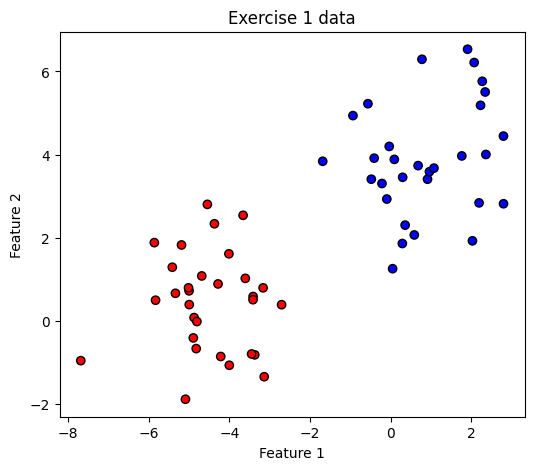

In [27]:
X1, y1 = make_blobs(n_samples=60, centers=2, cluster_std=1.2, random_state=3)

plt.figure(figsize=(6, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=y1, cmap="bwr", edgecolors="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Exercise 1 data")
plt.show()

**1(a) [8 marks]** Create a linear SVM with `C=1` and train it on `X1` and `y1`.

**1(b) [6 marks]** Draw the model with `plot_svm`.

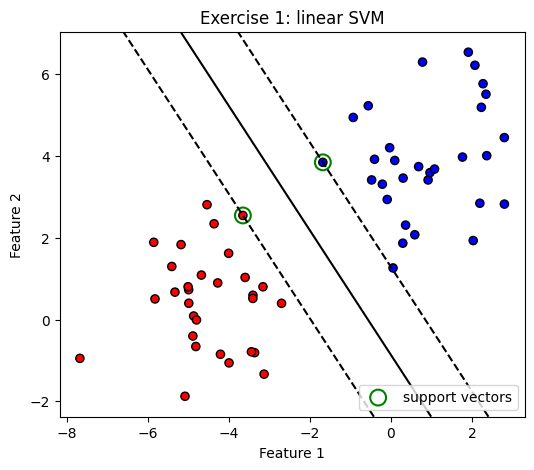

In [39]:
# 1(a) Create the model: the kernel should be "linear" and C should be 1
model1 = SVC(kernel="linear", C=1)

# 1(a) Train the model on X1 and y1
model1.fit(X1, y1)

# 1(b) Draw the model, the data and the title "Exercise 1: linear SVM"
plot_svm(model1, X1, y1, "Exercise 1: linear SVM")
plt.show()

**1(c) [6 marks]** Print the total number of support vectors.

**1(d) [6 marks]** Predict the class of the two new points `[0, 2]` and `[-8, -8]`.

In [32]:
# 1(c) Total number of support vectors (hint: len of model1.support_vectors_)
print("Number of support vectors:", len(model1.support_vectors_))

# 1(d) Predict the class of the new points
new_points = np.array([[0, 2],
                       [-8, -8]])
print("Predicted classes:", model1.predict(new_points))

Number of support vectors: 2
Predicted classes: [0 1]


**1(e) [4 marks]** If you change `C=1` to `C=0.01`, will the margin become **wider** or **narrower**?
Will the number of support vectors go **up** or **down**? Explain in one sentence.


**Your answer:** *(double-click this cell and type your answer here)*If we change C=1 to C=0.01, the margin becomes wider, and the number of support vectors will generally go up, because a smaller C allows more classification errors and creates a wider margin.

---
## Exercise 2: Linear versus kernel SVM, effect of C (30 marks)

This data has the shape of two moons. Run the cell to create it and split it into training and test sets.

In [41]:
X2, y2 = make_moons(n_samples=300, noise=0.25, random_state=1)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42)

print("Training samples:", len(X2_train), "   Test samples:", len(X2_test))

Training samples: 210    Test samples: 90


**2(a) [8 marks]** Train a **linear** SVM (`C=1`) on the training set and print its **test** accuracy.

**2(b) [8 marks]** Train an **RBF** SVM (`C=1`) on the training set and print its **test** accuracy.

**2(c) [4 marks]** Draw both models side by side with `plot_svm`, using the **training** data.

Linear SVM test accuracy: 0.8222222222222222
RBF SVM test accuracy: 0.9222222222222223


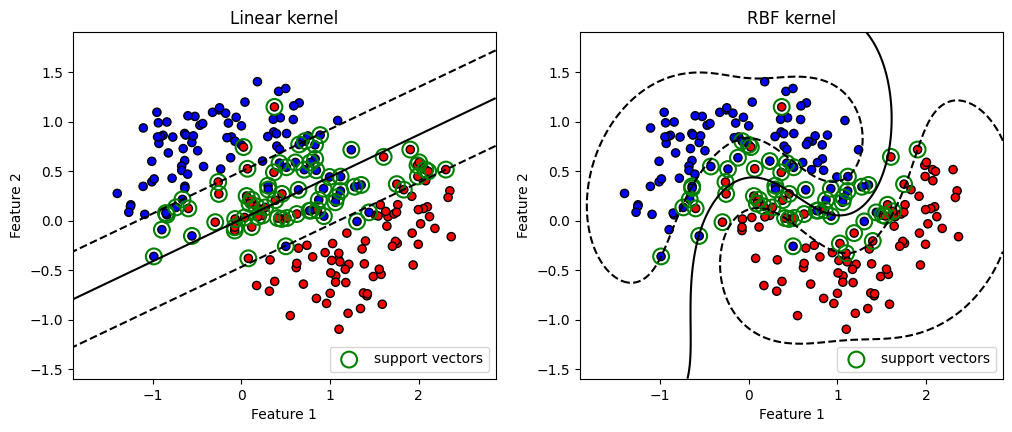

In [46]:
# 2(a) Linear SVM
linear2 = SVC(kernel="linear", C=1)
linear2.fit(X2_train, y2_train)
print("Linear SVM test accuracy:", linear2.score(X2_test, y2_test))

# 2(b) RBF SVM
rbf2 = SVC(kernel="rbf", C=1)
rbf2.fit(X2_train, y2_train)
print("RBF SVM test accuracy:", rbf2.score(X2_test, y2_test))

# 2(c) Draw both models on the training data
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_svm(linear2, X2_train, y2_train, "Linear kernel", ax=axes[0])
plot_svm(rbf2, X2_train, y2_train, "RBF kernel", ax=axes[1])
plt.show()

**2(d) [6 marks]** Complete the loop so that it trains an RBF SVM for each value of C and prints the
training accuracy and the test accuracy.

In [47]:
C_values = [0.01, 0.1, 1, 10, 100, 1000]

print("C       | train accuracy | test accuracy")
print("-" * 40)

for C in C_values:
    model = SVC(kernel="rbf", C=C)                 # use the current value of C
    model.fit(X2_train, y2_train)
    train_acc = model.score(X2_train, y2_train)                # accuracy on the TRAINING set
    test_acc = model.score(X2_test, y2_test)                 # accuracy on the TEST set
    print(f"{C:<7} | {train_acc:<14.3f} | {test_acc:.3f}")

C       | train accuracy | test accuracy
----------------------------------------
0.01    | 0.505          | 0.489
0.1     | 0.881          | 0.844
1       | 0.924          | 0.922
10      | 0.943          | 0.933
100     | 0.957          | 0.944
1000    | 0.967          | 0.933


(i) The RBF kernel works better on the moon-shaped data because it can create curved decision boundaries, while the linear kernel uses a straight line.

(ii) The best value of C is the C value that has the highest test accuracy in my table.**2(e) [4 marks]**
(i) Which kernel works better on the moon data, and why?
(ii) Which value of C gives the best **test** accuracy in your table?


**Your answer:** *(double-click this cell and type your answer here)*

---
## Exercise 3: Full evaluation on the Wine dataset (40 marks)

The Wine dataset contains chemical measurements of 178 wines from **3 different producers** (classes 0, 1 and 2).
There are 13 features, such as alcohol, magnesium and colour intensity.

SVM works with 3 classes in exactly the same way as with 2. The confusion matrix simply becomes 3 x 3.

Run the cell to load the data.

In [48]:
wine = load_wine()
X3 = wine.data
y3 = wine.target

print("Shape of X3:", X3.shape)
print("Class names:", wine.target_names)
print("Samples per class:", np.bincount(y3))

Shape of X3: (178, 13)
Class names: ['class_0' 'class_1' 'class_2']
Samples per class: [59 71 48]


**3(a) [6 marks]** Split the data: 25% for testing, `random_state=42`, and keep the class proportions with `stratify`.

**3(b) [8 marks]** Scale the features with `StandardScaler`. Remember the rule from A6.

**3(c) [6 marks]** Train an RBF SVM with `C=1` on the scaled training data and predict the test set.

In [49]:
# 3(a) Train / test split
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.25, random_state=42, stratify=y3)

# 3(b) Scaling
scaler3 = StandardScaler()
X3_train_scaled = scaler3.fit_transform(X3_train)     # learn from the training data AND transform it
X3_test_scaled = scaler3.transform(X3_test)       # only transform the test data

# 3(c) Train and predict
model3 = SVC(kernel="rbf", C=1)
model3.fit(X3_train_scaled, y3_train)
y3_pred = model3.predict(X3_test_scaled)
print("Done. First 10 predictions:", y3_pred[:10])

Done. First 10 predictions: [0 1 0 0 1 0 0 1 1 1]
